In [1]:
#Importing all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pydot
import seaborn as sns

from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV

import tensorflow as tf
import keras

from keras.models import Sequential
from keras.layers import Dense, Activation, Dropout
from keras.datasets import mnist
from keras.utils import to_categorical

from scikeras.wrappers import KerasClassifier


In [2]:
#%pip install pydot

In [3]:
import pydot
print(pydot.__version__)

4.0.1


In [4]:
#%pip install tensorflow

In [5]:
#%pip install keras


In [6]:
#%pip install scikeras

In [7]:
#splitting the train set and test according to the mnist data format
from keras.datasets import mnist
(X_train_digits,Y_train_digits),(X_test_digits,Y_test_digits) = mnist.load_data()

In [8]:
#checking the how the data is stored in Y_train
Y_train_digits

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

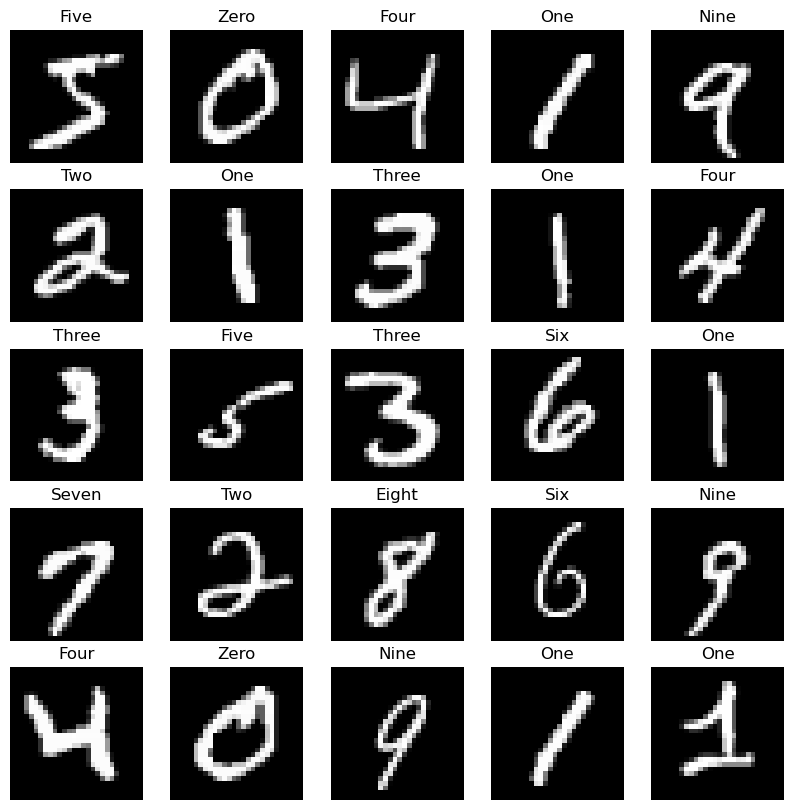

In [9]:
#importing matplotlib for graph
import matplotlib.pyplot as plt
#creating list called column names and storing all the required classes in names
col_names=['Zero','One','Two','Three','Four','Five','Six','Seven','Eight','Nine']
#creating an empty canvas 10x10 size
plt.figure(figsize=(10,10))
#ireating the first 25 digits of the data  from mnist digit dataset
for i in range(25):
#creating 5x5 matrix
    plt.subplot(5, 5, i+1)
#plt.imshow displays the digits in gray format

    plt.imshow(X_train_digits[i], cmap='gray')
#This will display the corresponding digit number names
    plt.title(col_names[Y_train_digits[i]])
    plt.axis('off')

plt.show()

In [10]:
#checking the shape of the x_train
X_train_digits.shape

(60000, 28, 28)

In [11]:
#Checking the shape of test set

X_test_digits.shape

(10000, 28, 28)

In [13]:
#ANN needs the shape in 2D format and we are reshaping the test set and train set accordingly using reshape function
X_train_digits=X_train_digits.reshape(60000,784)
X_test_digits=X_test_digits.reshape(10000,784)

In [16]:
#Checking how the y_train looks like
Y_train_digits.shape

(60000,)

In [17]:
#ANN output should be in onehot encoding, So we use to_categorical and pass the output variables and specify number of classes
Y_train_digits=to_categorical(Y_train_digits,num_classes=10)
Y_test_digits=to_categorical(Y_test_digits,num_classes=10)

In [19]:
#After converting to categorical, we are checking how the output variable looks like
Y_test_digits

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(10000, 10))

In [20]:
#After converting we are checking the shape of output variable and it has number of rows and columns 
Y_train_digits.shape

(60000, 10)

In [21]:
~Randomly checking the output variable
Y_train_digits[2]

array([0., 0., 0., 0., 1., 0., 0., 0., 0., 0.])

In [29]:
#Importing all the required libraries for creating ANN
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation, Dropout
from keras import layers
#We are loading empty model here
model = keras.Sequential([
#  Here we specify, no of neurons and input to the input layer.followed by creating  hidden layers and output layer
    layers.Dense(256, activation='relu', input_shape=(784,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='sigmoid')
])

C:\Users\gayut\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
#dense layer param cal=outputchannelnumber(inputlayerchannel+1)
    #param=356(784+)=200,960, ythis repeats for the rest
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 222,218 (868.04 KB)

 Trainable params: 222,218 (868.04 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
#We are compiling the model and we use loss function as categorical_crossentropy,optimizer="adam"  
#here adam will adjust the weight and bias based on the loss and here we use accuracy as our metrics
model.compile(loss="categorical_crossentropy",optimizer="adam",metrics=['Accuracy'])

import tensorflow as tf

print(tf.__version__)
print(tf.config.list_physical_devices('CPU'))

In [36]:
#We are creating the model here, we specify batch size as 100, 10 rounds of epochs and validating the data
history=model.fit(X_train_digits,Y_train_digits,batch_size=100,epochs=10,validation_data=(X_test_digits,Y_test_digits))

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - Accuracy: 0.8316 - loss: 1.4151 - val_Accuracy: 0.9155 - val_loss: 0.3364
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - Accuracy: 0.9343 - loss: 0.2466 - val_Accuracy: 0.9365 - val_loss: 0.2429
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - Accuracy: 0.9510 - loss: 0.1608 - val_Accuracy: 0.9436 - val_loss: 0.2101
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - Accuracy: 0.9588 - loss: 0.1269 - val_Accuracy: 0.9498 - val_loss: 0.1794
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - Accuracy: 0.9639 - loss: 0.1085 - val_Accuracy: 0.9572 - val_loss: 0.1589
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - Accuracy: 0.9659 - loss: 0.1001 - val_Accuracy: 0.9506 - val_loss: 0.1990
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - Accuracy: 0.9710 - loss: 0.0847 - val_Accuracy: 0.9536 - val_loss: 0.1656
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - Accuracy: 0.9696 - loss: 0.0894 - val_Accuracy:

In [52]:
#Prediction is happening here
y_predict=model.predict(X_test_digits)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [53]:
#Checking how the y_predict looks like
y_predict

array([[1.82798345e-07, 9.98527169e-01, 9.98955190e-01, ...,
        1.00000000e+00, 1.00093684e-08, 9.99999940e-01],
       [8.21220925e-10, 1.00000000e+00, 1.00000000e+00, ...,
        3.81803978e-03, 9.64680374e-01, 2.90992978e-18],
       [1.74970584e-04, 9.99999344e-01, 4.70156744e-02, ...,
        6.87332034e-01, 1.51490867e-01, 4.79204953e-01],
       ...,
       [1.95642766e-02, 9.65449810e-01, 3.78793210e-01, ...,
        9.98967528e-01, 9.85682964e-01, 9.99909043e-01],
       [1.91046759e-01, 1.20524057e-09, 1.34450942e-01, ...,
        2.65163802e-12, 9.99898195e-01, 3.56900244e-04],
       [7.91289835e-07, 2.13963568e-01, 5.66754716e-05, ...,
        1.47146618e-11, 8.80258810e-03, 8.82165696e-05]],
      shape=(10000, 10), dtype=float32)

In [54]:
#Here we use argmax, so the max of that array will be taken here
y_predicts=np.argmax(y_predict,axis=1)

In [55]:
#Checking y_predicts variable looks like after the argmax is done
y_predicts

array([7, 1, 1, ..., 4, 5, 6], shape=(10000,))

In [60]:
#we perform the same operation for test variable as well
y_test_digits_eval=np.argmax(Y_test_digits,axis=1)

In [61]:
#Checking the y_test
y_test_digits_eval

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [67]:
#Creating confusion matrix
cm=confusion_matrix(y_test_digits_eval,y_predicts)

In [68]:
cm

array([[ 962,    0,    1,    2,    2,    1,    7,    0,    3,    2],
       [   0, 1131,    1,    3,    0,    0,    0,    0,    0,    0],
       [   5,   55,  947,    8,    2,    0,    2,    5,    8,    0],
       [   0,    1,    5,  987,    0,    4,    0,    4,    9,    0],
       [   2,    6,    2,    0,  935,    0,   10,    2,    6,   19],
       [   5,    5,    1,   15,    1,  845,    9,    2,    3,    6],
       [   4,    7,    1,    0,    4,    5,  933,    0,    3,    1],
       [   3,   11,   11,   11,    2,    1,    0,  982,    3,    4],
       [   5,    3,   12,   11,    2,    6,    1,    2,  928,    4],
       [   3,    9,    0,   10,    6,    1,    0,    7,    9,  964]])

In [69]:
#we are creating the table for confusion matrix for more visibility
import pandas as pd

cm_table = pd.DataFrame(cm, index=range(10), columns=range(10))

display(cm_table)

,0,1,2,3,4,5,6,7,8,9
0,962,0,1,2,2,1,7,0,3,2
1,0,1131,1,3,0,0,0,0,0,0
2,5,55,947,8,2,0,2,5,8,0
3,0,1,5,987,0,4,0,4,9,0
4,2,6,2,0,935,0,10,2,6,19
5,5,5,1,15,1,845,9,2,3,6
6,4,7,1,0,4,5,933,0,3,1
7,3,11,11,11,2,1,0,982,3,4
8,5,3,12,11,2,6,1,2,928,4
9,3,9,0,10,6,1,0,7,9,964


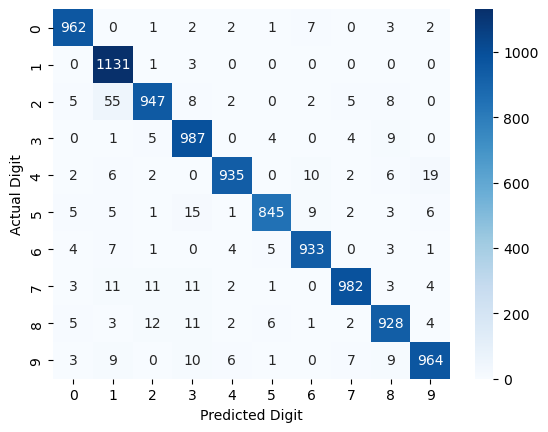

In [70]:
#we are creating heatmap
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Digit')
plt.ylabel('Actual Digit')
plt.show()

In [72]:
#we are creating classification report
from sklearn.metrics import classification_report
classification_report=classification_report(y_test_digits_eval,y_predicts)
print(classification_report)

              precision    recall  f1-score   support

           0       0.97      0.98      0.98       980
           1       0.92      1.00      0.96      1135
           2       0.97      0.92      0.94      1032
           3       0.94      0.98      0.96      1010
           4       0.98      0.95      0.97       982
           5       0.98      0.95      0.96       892
           6       0.97      0.97      0.97       958
           7       0.98      0.96      0.97      1028
           8       0.95      0.95      0.95       974
           9       0.96      0.96      0.96      1009

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000



In [74]:
#We are checking the available keys 
history.history.keys()

dict_keys(['Accuracy', 'loss', 'val_Accuracy', 'val_loss'])

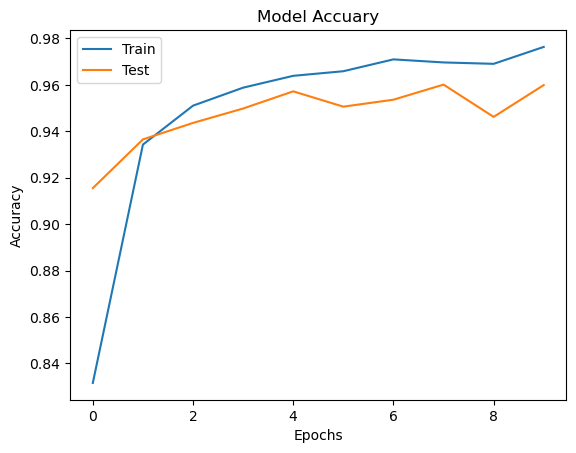

In [76]:
plt.plot(history.history['Accuracy'])
plt.plot(history.history['val_Accuracy'])
plt.title("Model Accuary")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Train","Test"],loc="best")
plt.show()